# Breakdown Voltage Computation (Reworked)


In [37]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Import packages

In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sys
sys.path.append('../')
import pylars

In [39]:
import pylars.utils.input
import pylars.utils.output
from pylars.analysis.breakdown import *
from pylars.plotting.plotprocessed import *

## Setup the run

In [40]:
run_number = 1
main_data_path = '../kadev/data/'
F_amp = 1
ADC_model = 'v1724'

In [41]:
base_run = pylars.utils.input.run(
    run_number,
    main_data_path,
    F_amp,
    ADC_model,
)

### initiate processor

In [42]:
sigma_level = 2
baseline_samples = 14_000

In [43]:
process = pylars.processing.rawprocessor.run_processor(
    base_run,
    'simple',
    sigma_level,
    baseline_samples,
)

### initiate dataset

In [44]:
temperature = 170
module = 0
channel = 'wf0'
processor = process

In [45]:
bvd = BV_dataset(
    base_run,
    temperature,
    module,
    channel,
    processor,
)

In [46]:
bvd.voltages = bvd.get_voltages_available()
print(f"Found voltages: \n {bvd.voltages}")
print(bvd.temp)

Found voltages: 
 [46.5 46.8 47.1 47.4 47.7 48.  48.3 48.6 48.9 49.2 49.5 49.8]
170


## Process Dataset

assuming the raw data is located at: main_data_path + "run" + run_number + "/data"

here eg. : "../kadev/data/run1/data"

as main_data_path = "../kadev/data/"
and run_number = 1

this processes the files and safes the processed data in the run directory as .hdf5 files.

If the processed files already exist you can skip the following cell and directly load the data.

In [47]:
for _voltage in bvd.voltages:
    print(f"Processing data for {_voltage} V: \n")
    
    df = process.process_datasets(
        'BV',
        _voltage,
        bvd.temp,
    )

    processed_data = pylars.utils.output.processed_dataset(
        base_run,
        'BV',
        _voltage,
        bvd.temp,
        base_run.main_data_path,
        process.hash,
    )
    processed_data.input_data(df)
    processed_data.save_data(type='hdf5')

Processing data for 46.5 V: 

Found 1 datasets. Ramping up processor!


Loading and processing datasets: 100%|███████████████████████████████████████████████████████████████████| 1/1 [00:11<00:00, 11.86s/it]


Saved file to: ../kadev/data/run1/BV_170.00_46.50-mrqweiq.h5
Processing data for 46.8 V: 

Found 1 datasets. Ramping up processor!


Loading and processing datasets: 100%|███████████████████████████████████████████████████████████████████| 1/1 [00:11<00:00, 11.15s/it]


Saved file to: ../kadev/data/run1/BV_170.00_46.80-mrqweiq.h5
Processing data for 47.1 V: 

Found 1 datasets. Ramping up processor!


Loading and processing datasets: 100%|███████████████████████████████████████████████████████████████████| 1/1 [00:11<00:00, 11.41s/it]


... (15 outputs left out)

Loading and processing datasets: 100%|███████████████████████████████████████████████████████████████████| 1/1 [00:11<00:00, 11.54s/it]


Saved file to: ../kadev/data/run1/BV_170.00_49.50-mrqweiq.h5
Processing data for 49.8 V: 

Found 1 datasets. Ramping up processor!


Loading and processing datasets: 100%|███████████████████████████████████████████████████████████████████| 1/1 [00:11<00:00, 11.15s/it]


Saved file to: ../kadev/data/run1/BV_170.00_49.80-mrqweiq.h5


In [48]:
bvd.load_processed_data()

Loading processed data for BV data at 170K: 100%|██████████████████████████████████████████████████████| 12/12 [00:01<00:00,  9.60it/s]


An ugly look at the dataset can be seen with

In [50]:
bvd.data

{np.float64(46.5):         module channel  wf_number  pulse_number  n_pulses     area  length  \
 0            0     wf0          0             0         2   2330.0       4   
 1            0     wf0          0             1         2   1870.0       4   
 2            0     wf0          1             0         1     -0.0       1   
 3            0     wf0          2             0         1  13900.0      10   
 4            0     wf0          3             0         3     -0.0       1   
 ...        ...     ...        ...           ...       ...      ...     ...   
 161582       0     wf0      99998             2         5     -0.0       1   
 161583       0     wf0      99998             3         5     -0.0       1   
 161584       0     wf0      99998             4         5     -0.0       1   
 161585       0     wf0      99999             0         2     -0.0       1   
 161586       0     wf0      99999             1         2     -0.0       1   
 
         position  amplitude  
 

A more beautiful view of the datasets can be achieved by looking at it through the processed_dataset class which already displays the dataset tabularised.

In [51]:
processed_data.data

,module,channel,wf_number,pulse_number,n_pulses,area,length,position,amplitude
0,0,wf0,0,0,1,62760.0,9,15,12978.0
1,0,wf0,1,0,1,119150.0,9,15,12048.0
2,0,wf0,2,0,1,57840.0,8,15,12904.0
3,0,wf0,3,0,1,38780.0,9,16,13318.0
4,0,wf0,4,0,1,122840.0,9,14,12017.0
...,...,...,...,...,...,...,...,...,...
110992,0,wf0,99995,0,1,64450.0,9,14,12960.0
110993,0,wf0,99996,0,1,93000.0,10,14,12678.0
110994,0,wf0,99997,0,1,71090.0,13,14,13232.0
110995,0,wf0,99998,0,1,63565.0,12,13,13275.0


## Check a Waveform

In [57]:
check_waveform_of_voltage = bvd.voltages[0]

In [55]:
bvd.voltages

array([46.5, 46.8, 47.1, 47.4, 47.7, 48. , 48.3, 48.6, 48.9, 49.2, 49.5,
       49.8])

The code below plots a histogram of the selected waveforms "position" entries, where a threshold is applied to the "length" quantity. Similarly any other quantity can be selected and plotted in different ways.

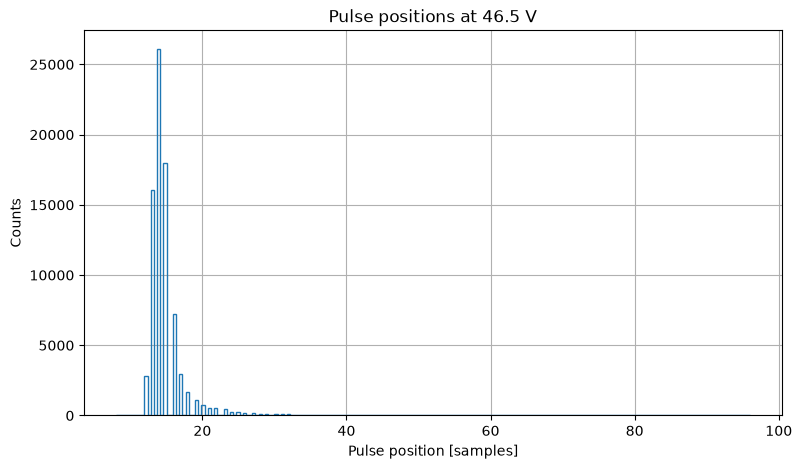

In [59]:
check_df = bvd.data[check_waveform_of_voltage]

plt.figure(figsize=(9,5))
plt.hist(
    check_df.loc[check_df["length"] > 3, "position"],
    bins = 200,
    histtype = "step",
)
plt.xlabel("Pulse position [samples]")
plt.ylabel("Counts")
plt.title(f"Pulse positions at {check_waveform_of_voltage} V")
plt.grid()
plt.show()

For convenience multiple plot options are predefined as functions in "pylars/plotting/plotprocessed.py". These include
- "plot_hist_area(df, bins=800, ax=None, color=None)",
- "plot_hist_length(df, bins=50, ax=None, color=None)",
- "plot_hist_position(df, bins=200, ax=None, color=None)" and
- "plot_hist_amplitude(df, bins=800, ax=None, color=None)".

Additionally "plot_3hists(df)" and "plot_4hists(df)" use the above functions to create quick histograms of area, length, position and area, amplitude, length, position respectively. This can be usefull for quick sanity checks.

**It is important to note that the above functions don't apply a threshold like we did in the manual example above!**

array([<Axes: xlabel='Area [integrated ADC counts]', ylabel='# events'>,
       <Axes: xlabel='Amplitude [ADC counts]', ylabel='# events'>,
       <Axes: xlabel='Length [# samples]', ylabel='# events'>,
       <Axes: xlabel='Position [sample #]', ylabel='# events'>],
      dtype=object)

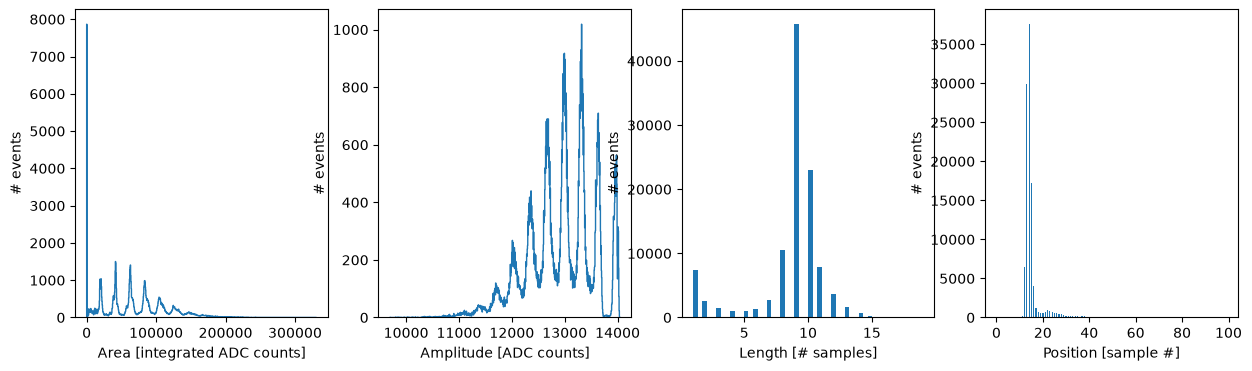

In [28]:
plot_4hists(df)

## Simple Breakdown Voltage Computation

This safes the fit plot in the "/figures" folder of the jupyter notebook location, which has to exist in the first place, and outputs the computed breakdown voltage, its error and the R^2 (goodness of fit) of the linear regression.

Since this is a simplified computation it doesn't include the real gain computation but rather computes the peak areas and treats their ratios as proportional to the gain (which is true but not 100 % accurate).

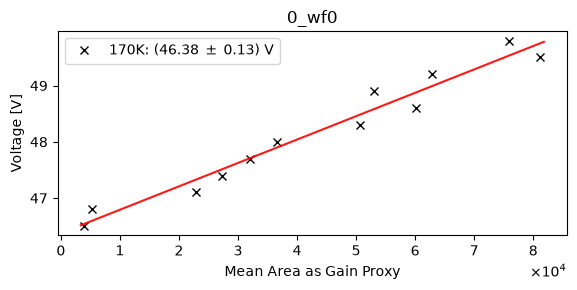

Computed breakdown voltage: 46.38 +- 0.13 V.


In [33]:
bv, bv_error, r2 = bvd.compute_BV_LED_simple(
    LED_position = 14,
    plot = True,
)
print(f"Computed breakdown voltage: {bv:.2f} +- {bv_error:.2f} V.")

## Thorough Breakdown Voltage Computation

requires a gain computation beforehand. The fitting procedure is essentially the same as for the simplified version above.

The only difference is that the dataset passed to "compute_BV_df(df)" requires a different format than the bvd dataset we have been using above. It requires the columns
- 'T',
- 'V', and
- 'gain'.

In contrast to the simple computation function above this returns the fit results as well as a new dataset containing additional columns 'BV' (breakdown voltage) and 'OV' (over-voltage), where 'OV' = 'V' - 'BV'.

In [34]:
bvd_with_gain = None

In [ ]:
#comp_bvd, lin_res_slope, bv, bv_error = bvd_with_gain.compute_BV_df()

## Breakdown Computation from Dark Count Rate Analysis

requires a finished DCR analysis and the resulting dataframe.

The below function essentially loads the processed DCR dataset and applies "compute_BV_df()" from above. In that sence it is just a convenient function to use in case a DCR analysis was previously done on that dataset, as this analysis also computes the gain which is required for "compute_BV_df()".

It returns only a dataframe containing channels
- 'T',
- 'module',
- 'channel',
- 'BV', and
- 'BV_error'.

In [35]:
processed_dcr = None

In [ ]:
#comp_bv_from_dcr = processed_dcr.compute(BV_DCRds_results())